# Validation 3 : ROC Curve Generation

## 1- Imports and Setup

In [1]:
import pandas as pd
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt

## 2- Load and Preprocess Data

Load the data from CSV files, sort by "File" and "Cell", and reset the indices.

In [2]:
expert_labels_path = "result_tool.csv"
tool_predictions_path = "manual_labeling.csv"

expert_labels = pd.read_csv(expert_labels_path)
tool_predictions = pd.read_csv(tool_predictions_path)

# Sort and reset indices
for df in [expert_labels, tool_predictions]:
    df.sort_values(["File", "Cell"], inplace=True)
    df.reset_index(drop=True, inplace=True)

## 3- Data Verification

Check data types and missing values, ensuring the expert and tool data are aligned.

In [3]:
print("Data types for expert_labels:")
print(expert_labels[['File', 'Cell']].dtypes)
print("\nData types for tool_predictions:")
print(tool_predictions[['File', 'Cell']].dtypes)

print("\nMissing values for expert_labels:")
print(expert_labels[['File', 'Cell']].isna().sum())
print("\nMissing values for tool_predictions:")
print(tool_predictions[['File', 'Cell']].isna().sum())

# Verify alignment of data
if not expert_labels[['File', 'Cell']].equals(tool_predictions[['File', 'Cell']]):
    raise ValueError("Expert and tool data are not aligned.")

Data types for expert_labels:
File    object
Cell     int64
dtype: object

Data types for tool_predictions:
File    object
Cell     int64
dtype: object

Missing values for expert_labels:
File    0
Cell    0
dtype: int64

Missing values for tool_predictions:
File    0
Cell    0
dtype: int64


## 4- ROC Curve Generation for Each Code Smell

Compute and plot the Receiver Operating Characteristic (ROC) curve for each specific code smell.

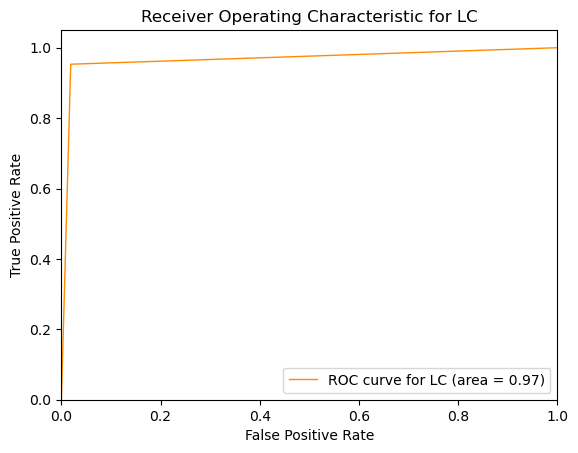

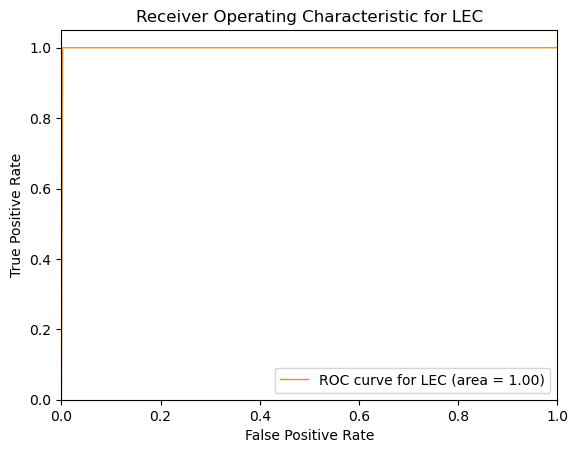

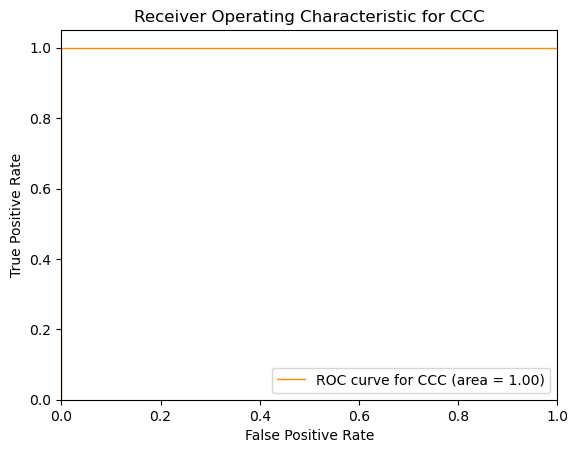

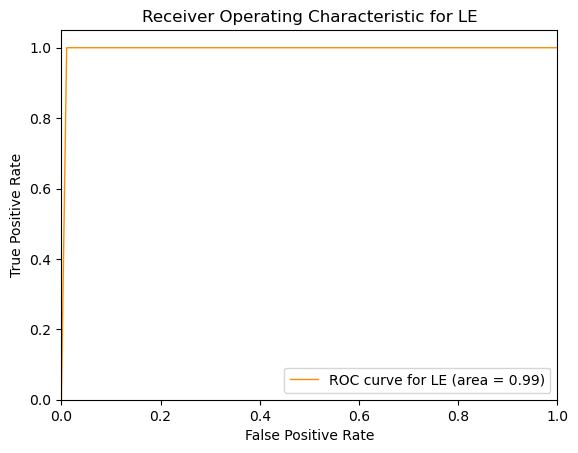

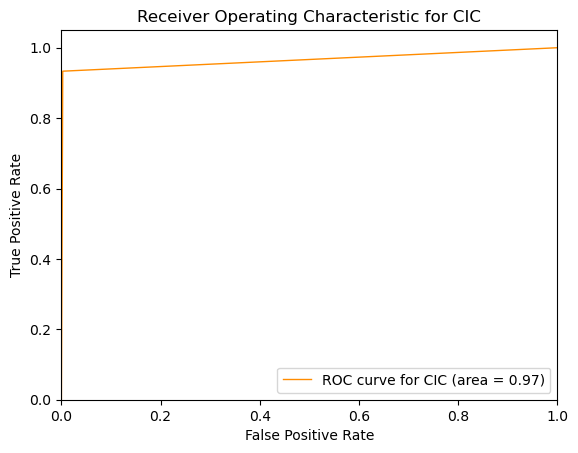

In [4]:
code_smells = [
    'LC', 'LEC', 'CCC', 
    'LE', 'CIC'
]

for smell in code_smells:
    y_true = expert_labels[smell]
    y_score = tool_predictions[smell]
    fpr, tpr, _ = roc_curve(y_true, y_score)
    roc_auc = auc(fpr, tpr)

    plt.figure()
    plt.plot(fpr, tpr, color='darkorange', lw=1, label=f'ROC curve for {smell} (area = {roc_auc:.2f})')
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('False Positive Rate')
    plt.ylabel('True Positive Rate')
    plt.title(f'Receiver Operating Characteristic for {smell}')
    plt.legend(loc="lower right")
    plt.show()